# Analisis Exploratorio de Datos (EDA)

Diagnostico inicial de `Data/bank-full.csv` siguiendo las pautas de `Requerimientos_examen/eda.md`. Se inspeccionan estructura, calidad, objetivo, distribuciones, valores atipicos y correlaciones. Los extremos se reportan para interpretacion de negocio, no se eliminan automaticamente.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
while not (ROOT / "Data" / "bank-full.csv").is_file() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.eda import count_iqr_outliers, plot_data_overview, summarize_data
from src.etl import load_bank_data

df = load_bank_data()
summary = summarize_data(df)
print("Registros y columnas:", summary["shape"])
print("Variables numericas:", summary["numeric_columns"])
print("Variables categoricas:", summary["categorical_columns"])
print("Duplicados exactos:", summary["duplicate_rows"])
print("Distribucion de suscripcion:")
print(pd.concat([summary["target_counts"].rename("Registros"), summary["target_percentages"].rename("Porcentaje")], axis=1))
print("Nulos por variable:")
display(summary["missing_by_column"].to_frame("Nulos"))
display(summary["numeric_summary"])
display(count_iqr_outliers(df))

Registros y columnas: (45211, 17)
Variables numericas: ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous', 'y']
Variables categoricas: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
Duplicados exactos: 0
Distribucion de suscripcion:
   Registros  Porcentaje
y                       
0      39922        88.3
1       5289        11.7
Nulos por variable:


,Nulos
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0


,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.936210,10.618762,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.163080,257.527812,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.197828,100.128746,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,275.0
y,45211.0,0.116985,0.321406,0.0,0.0,0.0,0.0,1.0


,Variable,Limite inferior IQR,Limite superior IQR,Valores atipicos,Porcentaje
0,previous,0.0,0.0,8257,18.263255
1,pdays,-1.0,-1.0,8257,18.263255
2,balance,-1962.0,3462.0,4729,10.459844
3,duration,-221.0,643.0,3235,7.155338
4,campaign,-2.0,6.0,3064,6.777112
5,age,10.5,70.5,487,1.077171
6,day,-11.5,40.5,0,0.000000


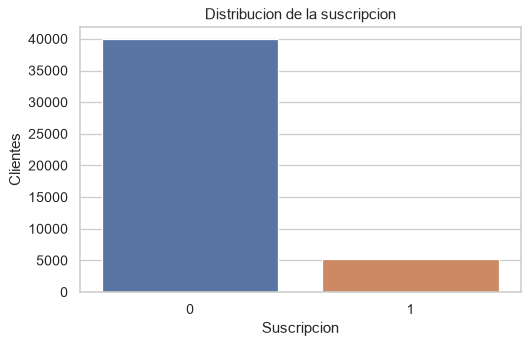

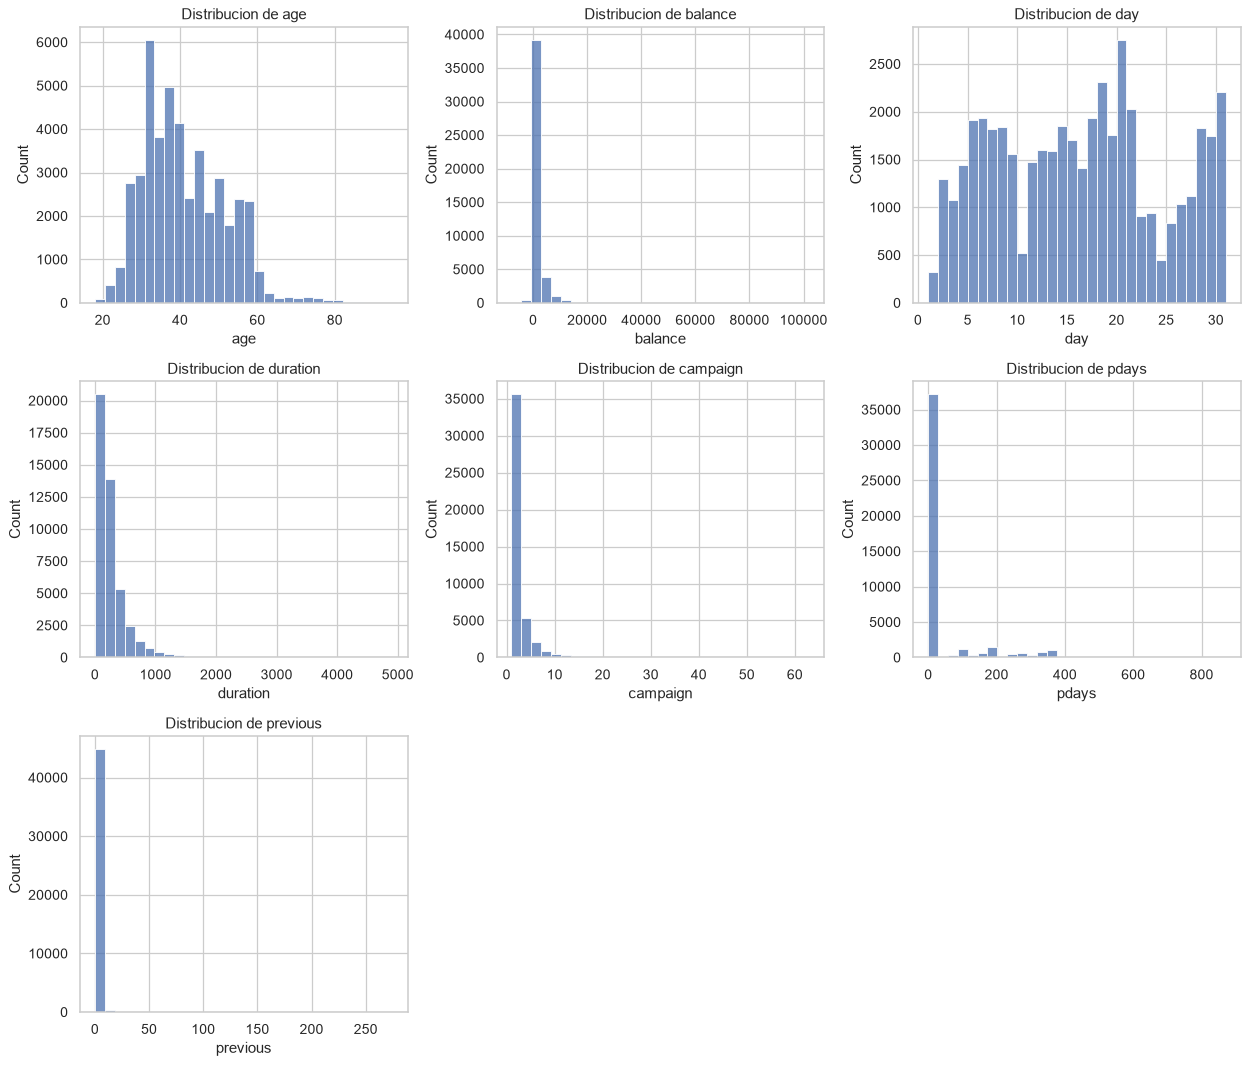

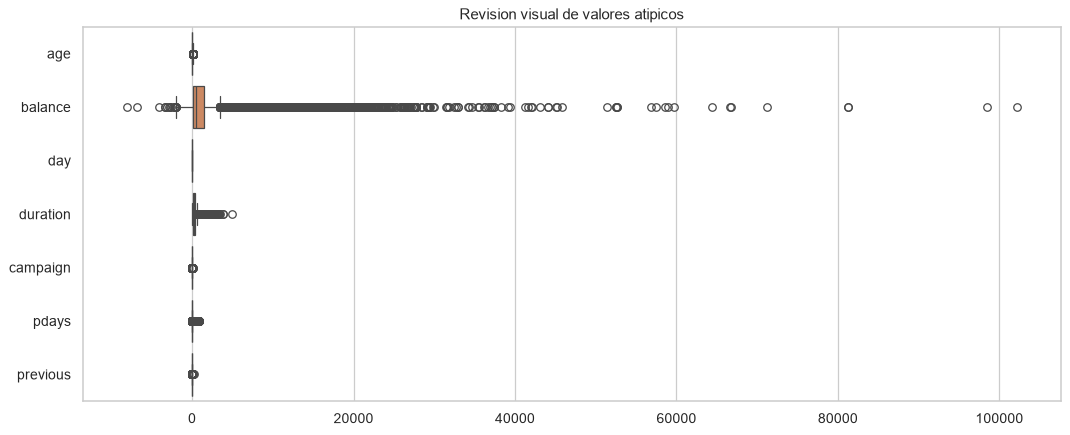

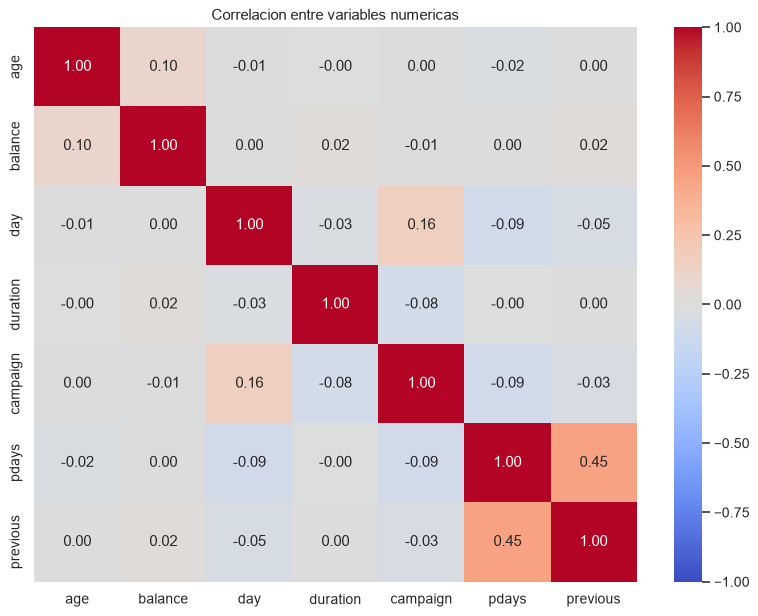

In [2]:
for figure in plot_data_overview(df):
    display(figure)
    plt.close(figure)

## Conclusiones del EDA

La suscripcion es minoritaria (cerca del 12%), asi que Accuracy por si sola puede ser enga?osa. Las categorias explicitas `unknown` se conservan como valores categoricos. La presencia de un valor extremo IQR no demuestra error; se mantienen los registros bancarios validos y se transforman los datos numericos dentro del pipeline de entrenamiento.